# Movie Review Sentiment Analysis Using TensorFlow

This notebook builds a neural network that classifies IMDB movie reviews as **positive** or **negative**.

## Project workflow
1. Import libraries
2. Load the IMDB dataset
3. Prepare training, validation, and test data
4. Build and train an embedding-based neural network
5. Evaluate the model and visualize training history
6. Predict the sentiment of custom movie reviews
7. Save the trained model

The IMDB dataset is loaded from `tf.keras.datasets`; an internet connection may be needed the first time it is downloaded.

## 1. Import libraries

In [1]:
import re
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2. Load the IMDB dataset

In [2]:
# Keep the 10,000 most frequent words
num_words = 10000
max_length = 500

(train_data, train_labels), (test_data, test_labels) = keras.datasets.imdb.load_data(
    num_words=num_words
)

print("Training reviews:", len(train_data))
print("Testing reviews:", len(test_data))
print("Example encoded review:", train_data[0][:20])
print("Example label:", train_labels[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training reviews: 25000
Testing reviews: 25000
Example encoded review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
Example label: 1


## 3. Prepare the data

In [3]:
# Pad or truncate reviews so every sequence has the same length
train_data = pad_sequences(
    train_data, maxlen=max_length, padding="post", truncating="post"
)
test_data = pad_sequences(
    test_data, maxlen=max_length, padding="post", truncating="post"
)

# Create a validation split from the training data.
# The test set is kept separate for final evaluation.
x_train, x_val, y_train, y_val = train_test_split(
    train_data,
    np.array(train_labels),
    test_size=0.2,
    random_state=42,
    stratify=train_labels
)

test_labels = np.array(test_labels)

print("Training shape:", x_train.shape)
print("Validation shape:", x_val.shape)
print("Testing shape:", test_data.shape)

Training shape: (20000, 500)
Validation shape: (5000, 500)
Testing shape: (25000, 500)


## 4. Build the neural network

In [4]:
model = keras.Sequential([
    layers.Embedding(input_dim=num_words, output_dim=16, input_length=max_length),
    layers.GlobalAveragePooling1D(),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 5. Train the model

In [5]:
epochs = 10
batch_size = 512

history = model.fit(
    x_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(x_val, y_val),
    verbose=1
)

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 111ms/step - accuracy: 0.5501 - loss: 0.6915 - val_accuracy: 0.5944 - val_loss: 0.6878
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 75ms/step - accuracy: 0.6047 - loss: 0.6840 - val_accuracy: 0.5580 - val_loss: 0.6782
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 75ms/step - accuracy: 0.6156 - loss: 0.6678 - val_accuracy: 0.6160 - val_loss: 0.6591
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 81ms/step - accuracy: 0.6808 - loss: 0.6400 - val_accuracy: 0.6864 - val_loss: 0.6253
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - accuracy: 0.7592 - loss: 0.5975 - val_accuracy: 0.7224 - val_loss: 0.5849
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 76ms/step - accuracy: 0.7708 - loss: 0.5523 - val_accuracy: 0.7884 - val_loss: 0.5369
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 99ms/step - accuracy: 0.8026 - loss: 0.5046 - val_accuracy: 0.8124 - val_loss: 0.4932
Epoch 8/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 127ms/step - accuracy: 0.8030 - loss: 0.4709 - val_accuracy: 0.7748 

## 6. Evaluate the model

In [6]:
test_loss, test_accuracy = model.evaluate(test_data, test_labels, verbose=0)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

Test loss: 0.4404
Test accuracy: 0.7916
Test accuracy: 79.16%


## 7. Visualize accuracy and loss

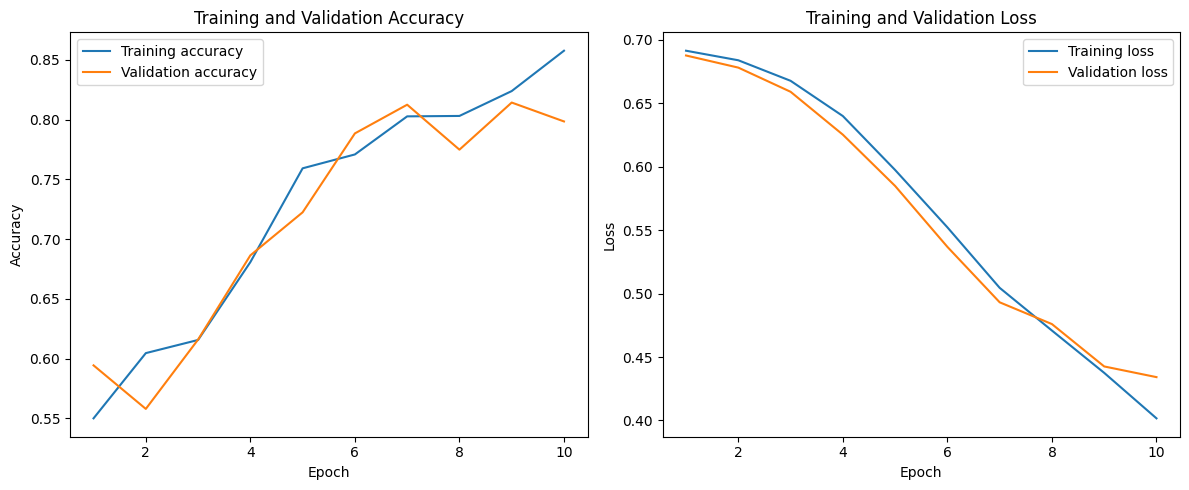

In [7]:
epochs_range = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history["accuracy"], label="Training accuracy")
plt.plot(epochs_range, history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history["loss"], label="Training loss")
plt.plot(epochs_range, history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 8. Predict sentiment for custom reviews

The IMDB dataset contains integer-encoded words rather than a separate `Tokenizer` object. The helper below uses the word index provided by the dataset, so it does not depend on an undefined tokenizer.

In [8]:
# Get the same word-to-integer mapping used by the IMDB dataset
word_index = keras.datasets.imdb.get_word_index()

def encode_review(review):
    # Match the basic lowercase, punctuation-cleaned word format used by IMDB.
    cleaned_review = re.sub(r"[^a-z0-9 ]", " ", review.lower())
    words = cleaned_review.split()

    # IMDB reserves: 0 = padding, 1 = start, 2 = out-of-vocabulary.
    # Regular word indexes are shifted by 3.
    encoded = [1]

    for word in words:
        original_index = word_index.get(word)

        if original_index is None:
            index = 2
        else:
            index = original_index + 3
            if index >= num_words:
                index = 2

        encoded.append(index)

    return pad_sequences(
        [encoded], maxlen=max_length, padding="post", truncating="post"
    )

def predict_review(review):
    if not isinstance(review, str) or not review.strip():
        raise ValueError("Please enter a non-empty review.")

    review_data = encode_review(review)
    probability = float(model.predict(review_data, verbose=0)[0][0])

    sentiment = "Positive" if probability >= 0.5 else "Negative"
    confidence = probability if probability >= 0.5 else 1 - probability

    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print(f"Confidence: {confidence * 100:.2f}%")

    return sentiment, probability

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


### Try sample reviews

In [9]:
positive_review = "This movie was wonderful, the acting was excellent and I really enjoyed it."
negative_review = "This was a boring movie with a terrible story and poor acting."

predict_review(positive_review)
print()
predict_review(negative_review)

Review: This movie was wonderful, the acting was excellent and I really enjoyed it.
Predicted sentiment: Negative
Confidence: 62.36%

Review: This was a boring movie with a terrible story and poor acting.
Predicted sentiment: Negative
Confidence: 79.69%


('Negative', 0.20305567979812622)

## 9. Save the trained model

In [10]:
model.save("movie_review_sentiment_model.keras")
print("Model saved as movie_review_sentiment_model.keras")

Model saved as movie_review_sentiment_model.keras


## 10. Conclusion

This project demonstrates binary text classification with TensorFlow/Keras. The model learns word representations through an embedding layer and predicts whether an IMDB movie review expresses positive or negative sentiment.

**Note:** The displayed test accuracy is produced when the notebook is run. It is intentionally not hard-coded in this notebook or README.